# 05 — Análisis

**Práctica 4 · Logística del Valle** (punto 8 del enunciado)

Respondemos cuatro preguntas con experimentos adicionales sobre el mismo modelo:

1. ¿Cuánto aporta cambiar las rutas, y de dónde viene esa mejora?
2. ¿Qué sucede al aumentar la demanda?
3. ¿En qué condiciones la cantidad de vehículos se vuelve una limitación?
4. ¿Qué tan robustas son las conclusiones, y qué aspectos de la operación real no representa la simulación?

Todos los experimentos usan 30 repeticiones (semillas 1–30) y números aleatorios comunes: en cada semilla, todas
las políticas comparadas reciben los mismos pedidos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import experimentos as e
from src import grafo as g
from src import rutas as r
from src import simulacion as s
from src.graficas import COLOR_POLITICA

G = g.construir_grafo(g.cargar_matriz())
SALIDA = Path("resultados")
REPETICIONES = 30
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

ACTUAL, _ = s.rutas_politica(G, "Actual")
RECOMENDADA, _ = s.rutas_politica(G, "Recomendada")
ciclo = lambda rutas: np.mean([rr["ida"][1] + rr["regreso"][1] for rr in rutas.values()])
CICLO = {"Actual": ciclo(ACTUAL), "Recomendada": ciclo(RECOMENDADA)}
print("Ciclo promedio por pedido (min):", {k: round(v, 1) for k, v in CICLO.items()})

Ciclo promedio por pedido (min): {'Actual': np.float64(113.5), 'Recomendada': np.float64(79.5)}


## 1. ¿Cuánto aporta cambiar las rutas?

### 1.1 Magnitud del efecto

Con 8 vehículos y los mismos pedidos (resultados del notebook 04):

In [2]:
datos = pd.read_csv(SALIDA / "experimentos.csv")
metricas = ["puntualidad (%)", "espera promedio (min)", "solicitud→entrega promedio (min)", "tiempo adicional (min)"]
medias = datos.groupby(["escenario", "política"], sort=False)[metricas].mean().unstack("política")
aporte = pd.DataFrame({
    m: medias[(m, "Recomendada")] - medias[(m, "Actual")] for m in metricas
})
aporte["mejora relativa del tiempo solicitud→entrega (%)"] = (
    100 * -aporte["solicitud→entrega promedio (min)"] / medias[("solicitud→entrega promedio (min)", "Actual")])
aporte

,puntualidad (%),espera promedio (min),solicitud→entrega promedio (min),tiempo adicional (min),mejora relativa del tiempo solicitud→entrega (%)
escenario,,,,,
Normal,42.5,-15.0,-36.8,-55.1,49.5
Semana Santa,59.7,-66.3,-87.8,-181.6,62.6
Navidad,10.6,-148.4,-170.0,-340.7,49.0


### 1.2 ¿De dónde viene la mejora?

Para separar los efectos, simulamos dos políticas intermedias con los mismos pedidos:

| Política | Ida | Regreso |
|---|---|---|
| **Actual** | Hojas de despacho | Ida invertida |
| **Solo N40** | Dijkstra para N40; hojas de despacho para el resto | Dijkstra para N40; ida invertida para el resto |
| **Solo ida óptima** | Dijkstra | Ida actual invertida |
| **Recomendada** | Dijkstra | Dijkstra |

- *Solo N40* mide cuánto se gana corrigiendo únicamente la ruta que nunca puede ser puntual.
- *Solo ida óptima* vs. *Recomendada* mide cuánto aporta calcular el **regreso** por separado. El regreso no afecta la
  puntualidad del pedido que se entrega, pero sí cuándo queda libre el vehículo para el siguiente.

In [3]:
politicas = {
    "Actual": ACTUAL,
    "Solo N40": {d: (RECOMENDADA[d] if d == "N40" else ACTUAL[d]) for d in g.DESTINOS},
    "Solo ida óptima": {d: {"ida": RECOMENDADA[d]["ida"], "regreso": ACTUAL[d]["regreso"]} for d in g.DESTINOS},
    "Recomendada": RECOMENDADA,
}
for nombre, rutas in politicas.items():
    print(f"{nombre:>16}: ciclo promedio {ciclo(rutas):.1f} min")

descomposicion = e.correr_politicas(politicas, repeticiones=REPETICIONES)
tabla_desc = (descomposicion.groupby(["escenario", "política"], sort=False)[metricas].mean())
tabla_desc.to_csv(SALIDA / "descomposicion_rutas.csv")
tabla_desc

          Actual: ciclo promedio 113.5 min
        Solo N40: ciclo promedio 94.0 min
 Solo ida óptima: ciclo promedio 91.8 min
     Recomendada: ciclo promedio 79.5 min


puntualidad (%)  espera promedio (min)  \
escenario    política                                                  
Normal       Actual                      56.1                   17.1   
             Solo N40                    93.6                    5.3   
             Solo ida óptima             95.3                    5.1   
             Recomendada                 98.7                    2.1   
Semana Santa Actual                      21.2                   83.8   
             Solo N40                    44.5                   45.2   
             Solo ida óptima             59.5                   37.0   
             Recomendada                 81.0                   17.5   
Navidad      Actual                       8.7                  290.2   
             Solo N40                    11.7                  210.1   
             Solo ida óptima             15.9                  194.9   
             Recomendada                 19.4                  141.8   

                              solicitud→entrega promedio (min)  \
escenario    política                                            
Normal       Actual                                       74.4   
             Solo N40                                     50.8   
             Solo ida óptima                              40.6   
             Recomendada                                  37.6   
Semana Santa Actual                                      140.2   
             Solo N40                                     90.5   
             Solo ida óptima                              71.9   
             Recomendada                                  52.4   
Navidad      Actual                                      346.7   
             Solo N40                                    255.4   
             Solo ida óptima                             229.8   
             Recomendada                                 176.7   

                              tiempo adicional (min)  
escenario    política                                 
Normal       Actual                             78.6  
             Solo N40                           34.3  
             Solo ida óptima                    28.3  
             Recomendada                        23.5  
Semana Santa Actual                            242.9  
             Solo N40                          132.4  
             Solo ida óptima                   107.7  
             Recomendada                        61.4  
Navidad      Actual                            672.4  
             Solo N40                          478.8  
             Solo ida óptima                   442.1  
             Recomendada                       331.7

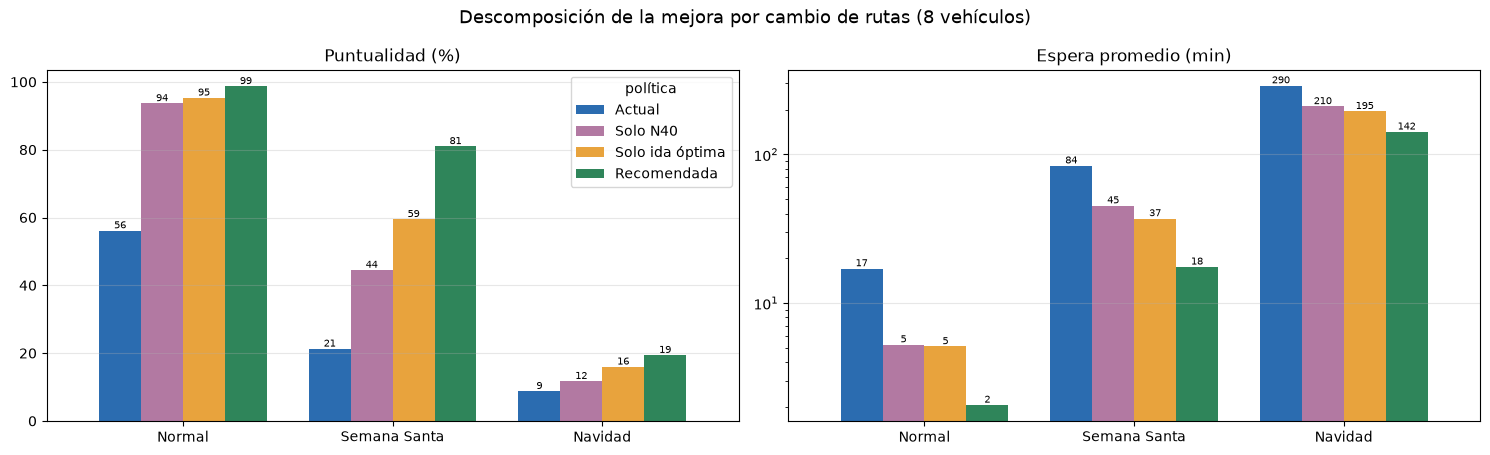

In [4]:
colores = {"Actual": COLOR_POLITICA["Actual"], "Solo N40": "#b279a2",
           "Solo ida óptima": "#e8a33d", "Recomendada": COLOR_POLITICA["Recomendada"]}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, metrica in zip(axes, ["puntualidad (%)", "espera promedio (min)"]):
    datos_g = tabla_desc[metrica].unstack("política")[list(politicas)].loc[list(s.ESCENARIOS)]
    datos_g.plot.bar(ax=ax, color=[colores[p] for p in datos_g.columns], rot=0, width=0.8)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.0f", fontsize=7)
    ax.set_title(metrica.capitalize())
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
axes[1].set_yscale("log")
axes[1].get_legend().remove()
fig.suptitle("Descomposición de la mejora por cambio de rutas (8 vehículos)", fontsize=13)
fig.tight_layout()
fig.savefig(SALIDA / "descomposicion_rutas.png", dpi=130, bbox_inches="tight")
plt.show()

**Lectura**

- Con **demanda baja** (Normal), casi toda la mejora en puntualidad viene de corregir N40: pasa de 56 % a ~94 %.
  El problema dominante es que una ruta excede el umbral, no la capacidad.
- Con **demanda alta** (Semana Santa), corregir solo N40 deja la puntualidad en ~45 %. Ahí importa acortar **todos**
  los ciclos, porque el cuello de botella es la disponibilidad de vehículos.
- Optimizar también el **regreso** agrega ~20 puntos de puntualidad en Semana Santa (de ~60 % a 81 %), aunque el regreso no
  forme parte del tiempo de entrega: un vehículo que vuelve antes atiende antes al siguiente pedido de la cola.

### 1.3 Equivalencia en vehículos

¿Cuántos vehículos necesitaría la política actual para igualar la espera que logra la recomendada con 8?
Usamos el barrido de flota del notebook 04.

In [5]:
barrido_flota = pd.read_csv(SALIDA / "barrido_flota.csv")
nombres = {v: k for k, v in s.ESCENARIOS.items()}
filas = []
for tasa in s.ESCENARIOS.values():
    sub = barrido_flota[barrido_flota["pedidos por hora"] == tasa]
    ref = sub[(sub["política"] == "Recomendada") & (sub["vehículos"] == 8)].iloc[0]
    actual = sub[sub["política"] == "Actual"]
    k = actual[actual["espera promedio (min)"] <= ref["espera promedio (min)"]]["vehículos"].min()
    filas.append({"escenario": nombres[tasa],
                  "espera con rutas recomendadas y 8 vehículos (min)": ref["espera promedio (min)"],
                  "vehículos que necesita la política actual": k,
                  "vehículos equivalentes al cambio de rutas": k - 8,
                  "puntualidad actual con esa flota (%)": actual[actual["vehículos"] == k]["puntualidad (%)"].iloc[0],
                  "puntualidad recomendada con 8 (%)": ref["puntualidad (%)"]})
equivalencia = pd.DataFrame(filas).set_index("escenario")
equivalencia.to_csv(SALIDA / "equivalencia_vehiculos.csv")
equivalencia

,espera con rutas recomendadas y 8 vehículos (min),vehículos que necesita la política actual,vehículos equivalentes al cambio de rutas,puntualidad actual con esa flota (%),puntualidad recomendada con 8 (%)
escenario,,,,,
Normal,2.1,11,3,73.0,98.7
Semana Santa,17.5,11,3,55.4,81.0
Navidad,141.8,12,4,17.6,19.4


Cambiar las rutas equivale a comprar **3 o 4 vehículos más** en cuanto a espera, y aun así la política actual con esa
flota mayor queda por debajo en puntualidad, porque no corrige N40.

## 2. ¿Qué sucede al aumentar la demanda?

Recorremos todas las combinaciones de demanda (2 a 14 pedidos/h) y flota (4 a 20 vehículos), con 30 repeticiones cada una.
La curva blanca marca la **capacidad teórica**: el número de vehículos con el que la flota estaría ocupada el 100 % del
tiempo, `k = λ × ciclo / 60`.

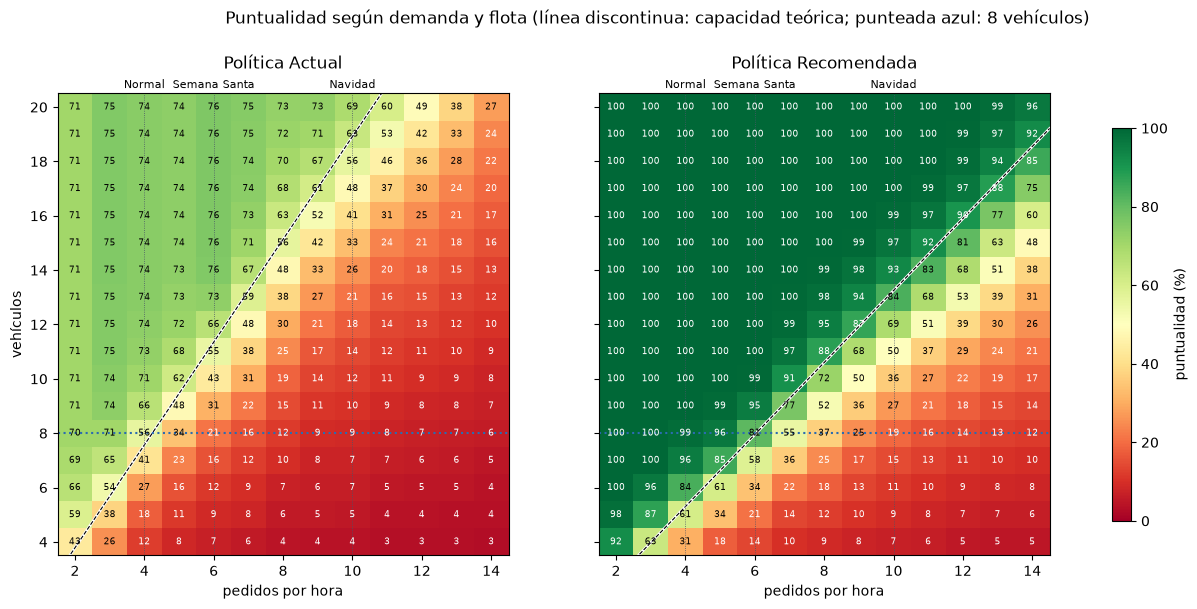

In [6]:
tasas = list(range(2, 15))
flotas = list(range(4, 21))
mapa = e.barrido(tasas=tasas, vehiculos=flotas, repeticiones=REPETICIONES, G=G)
mapa.to_csv(SALIDA / "mapa_demanda_flota.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, politica in zip(axes, s.POLITICAS):
    tabla = mapa[mapa["política"] == politica].pivot(index="vehículos", columns="pedidos por hora",
                                                    values="puntualidad (%)")
    im = ax.imshow(tabla.values, origin="lower", aspect="auto", cmap="RdYlGn", vmin=0, vmax=100,
                   extent=[tasas[0] - 0.5, tasas[-1] + 0.5, flotas[0] - 0.5, flotas[-1] + 0.5])
    for i, k in enumerate(tabla.index):
        for j, t in enumerate(tabla.columns):
            v = tabla.iloc[i, j]
            ax.text(t, k, f"{v:.0f}", ha="center", va="center", fontsize=6.5,
                    color="black" if 25 < v < 85 else "white")
    x = np.linspace(tasas[0] - 0.5, tasas[-1] + 0.5, 100)
    ax.plot(x, x * CICLO[politica] / 60, color="white", lw=2)
    ax.plot(x, x * CICLO[politica] / 60, color="black", lw=0.8, ls="--")
    ax.axhline(8, color="#2b6cb0", lw=1.5, ls=":")
    for t, nombre in nombres.items():
        ax.axvline(t, color="#4a5568", lw=0.6, ls=":")
        ax.text(t, flotas[-1] + 0.7, nombre, ha="center", fontsize=8)
    ax.set_xlim(tasas[0] - 0.5, tasas[-1] + 0.5)
    ax.set_ylim(flotas[0] - 0.5, flotas[-1] + 0.5)
    ax.set_title(f"Política {politica}", pad=18)
    ax.set_xlabel("pedidos por hora")
axes[0].set_ylabel("vehículos")
fig.colorbar(im, ax=axes, label="puntualidad (%)", shrink=0.85)
fig.suptitle("Puntualidad según demanda y flota (línea discontinua: capacidad teórica; punteada azul: 8 vehículos)",
             fontsize=12, y=1.02)
fig.savefig(SALIDA / "mapa_demanda_flota.png", dpi=130, bbox_inches="tight")
plt.show()

- Con la política **actual**, el mapa nunca llega al verde intenso: aunque sobren vehículos, la puntualidad se queda en ~75 %
  por N40.
- Con la **recomendada**, la frontera entre verde y rojo sigue la capacidad teórica, desplazada hacia arriba: hace falta
  una flota algo **mayor** que la teórica para absorber la variabilidad de las llegadas.
- Para una flota fija, la puntualidad **no cae de forma gradual**: se mantiene alta y se desploma en pocos pedidos/h
  cuando la demanda se acerca a la capacidad.

## 3. ¿Cuándo la flota se vuelve una limitación?

Medimos la carga de la flota con el **factor de utilización teórico**:

$$\rho = \frac{\lambda \cdot \bar{C}}{60 \cdot k}$$

donde λ son los pedidos por hora, $\bar{C}$ el ciclo promedio (ida + regreso) y k los vehículos. ρ = 1 significa que la
flota apenas alcanza para la demanda si nunca está ociosa.

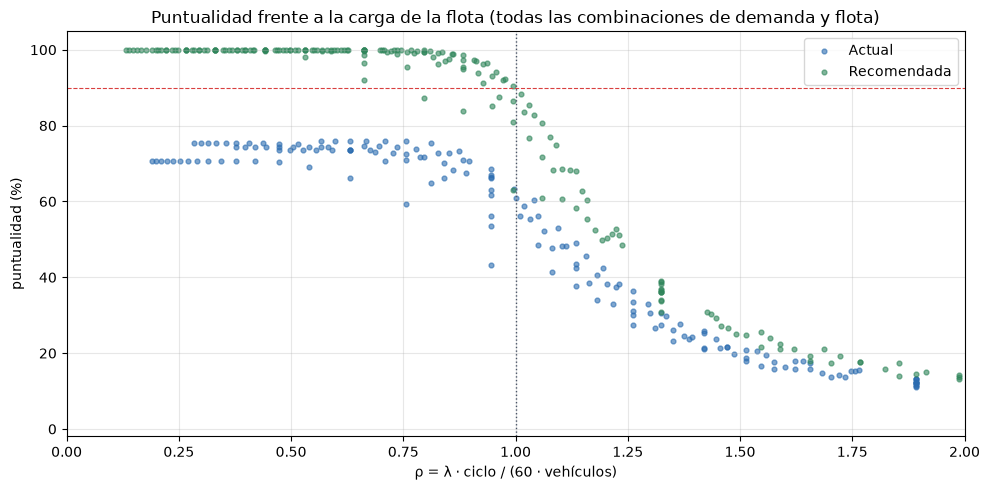

In [7]:
mapa["rho"] = mapa["pedidos por hora"] * mapa["política"].map(CICLO) / (60 * mapa["vehículos"])

fig, ax = plt.subplots(figsize=(10, 5))
for politica in s.POLITICAS:
    sub = mapa[mapa["política"] == politica]
    ax.scatter(sub["rho"], sub["puntualidad (%)"], s=12, alpha=0.6, color=COLOR_POLITICA[politica], label=politica)
ax.axhline(90, color="#d93f3f", ls="--", lw=0.8)
ax.axvline(1, color="#4a5568", ls=":", lw=1)
ax.set_xlim(0, 2)
ax.set_xlabel("ρ = λ · ciclo / (60 · vehículos)")
ax.set_ylabel("puntualidad (%)")
ax.set_title("Puntualidad frente a la carga de la flota (todas las combinaciones de demanda y flota)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(SALIDA / "puntualidad_vs_rho.png", dpi=130, bbox_inches="tight")
plt.show()

In [8]:
rec = mapa[mapa["política"] == "Recomendada"]
cortes = pd.cut(rec["rho"], [0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2, 1.5, 3])
por_rho = rec.groupby(cortes, observed=True)["puntualidad (%)"].agg(["min", "mean", "max", "count"])
por_rho.index.name = "ρ (política recomendada)"
por_rho

,min,mean,max,count
ρ (política recomendada),,,,
"(0.0, 0.5]",99.7,100.0,100.0,52
"(0.5, 0.6]",98.1,99.8,100.0,15
"(0.6, 0.7]",92.1,99.1,100.0,15
"(0.7, 0.8]",87.2,98.6,100.0,17
"(0.8, 0.9]",83.9,96.8,99.7,14
"(0.9, 1.0]",63.0,89.8,97.2,16
"(1.0, 1.2]",49.9,69.3,88.3,21
"(1.2, 1.5]",25.1,37.3,52.8,22
"(1.5, 3.0]",7.5,14.9,25.7,40


In [9]:
filas = []
for tasa in tasas:
    sub = rec[(rec["pedidos por hora"] == tasa) & (rec["puntualidad (%)"] >= 90)]
    k = sub["vehículos"].min()
    filas.append({"pedidos por hora": tasa,
                  "vehículos para ρ = 1": tasa * CICLO["Recomendada"] / 60,
                  "vehículos para ≥ 90 % puntual": k,
                  "ρ con esa flota": tasa * CICLO["Recomendada"] / (60 * k) if pd.notna(k) else np.nan})
flota_necesaria = pd.DataFrame(filas).set_index("pedidos por hora")
flota_necesaria.to_csv(SALIDA / "flota_necesaria.csv")
flota_necesaria

,vehículos para ρ = 1,vehículos para ≥ 90 % puntual,ρ con esa flota
pedidos por hora,,,
2,2.6,4,0.7
3,4.0,6,0.7
4,5.3,7,0.8
5,6.6,8,0.8
6,8.0,9,0.9
7,9.3,10,0.9
8,10.6,12,0.9
9,11.9,13,0.9
10,13.2,14,0.9


**Regla práctica:** con las rutas recomendadas, la puntualidad promedio se mantiene sobre 95 % mientras ρ ≤ 0.9, baja a
~70 % con ρ entre 1 y 1.2, y cae por debajo de 40 % cuando ρ > 1.2. Las flotas pequeñas necesitan más holgura
(ρ ≈ 0.7–0.8 para llegar al 90 %) que las grandes (ρ ≈ 1), porque con más vehículos es más probable que alguno se libere
pronto. Con la flota actual de 8 vehículos:

| Escenario | ρ actual | ρ recomendada | Diagnóstico |
|---|---|---|---|
| Normal (4/h) | 0.95 | 0.66 | Las rutas actuales ya saturan la flota; con las recomendadas hay holgura |
| Semana Santa (6/h) | 1.42 | 0.99 | Sin cambiar rutas la flota es insuficiente; con rutas recomendadas está en el límite |
| Navidad (10/h) | 2.36 | 1.66 | La flota es la limitación con cualquier ruta: hacen falta ~14 vehículos |

## 4. Robustez de las conclusiones

### 4.1 Tiempo de descarga en el destino

El modelo supone que la entrega es instantánea al llegar. Probamos 5, 10 y 15 minutos de descarga.

In [10]:
filas = []
for descarga in [0, 5, 10, 15]:
    df = e.correr_politicas({"Actual": ACTUAL, "Recomendada": RECOMENDADA}, repeticiones=REPETICIONES,
                            tiempo_entrega=descarga)
    tabla = df.groupby(["escenario", "política"], sort=False)["puntualidad (%)"].mean()
    filas.append(tabla.rename(f"{descarga} min"))
sensibilidad = pd.concat(filas, axis=1)
sensibilidad.to_csv(SALIDA / "sensibilidad_descarga.csv")
sensibilidad

0 min  5 min  10 min  15 min
escenario    política                                 
Normal       Actual        56.1   50.7    43.8    37.9
             Recomendada   98.7   97.0    94.1    90.0
Semana Santa Actual        21.2   17.9    15.7    14.4
             Recomendada   81.0   68.1    54.1    42.0
Navidad      Actual         8.7    8.2     8.1     8.0
             Recomendada   19.4   16.1    14.0    12.2

La política recomendada sigue siendo mejor con cualquier tiempo de descarga. Sin embargo, el diagnóstico de **Semana
Santa es sensible** a este supuesto: con 15 minutos de descarga su puntualidad cae de 81 % a ~42 %, porque cada
pedido ocupa al vehículo más tiempo y ρ supera 1. Medir el tiempo real de descarga es prioritario antes de decidir el
tamaño de la flota para temporadas altas.

### 4.2 Incidentes viales: ¿vale la pena recalcular las rutas?

Congestionamos el tramo **N09 → N01** (entrada a la bodega; el más crítico según el notebook 01) de 7 a 30 minutos y
comparamos tres respuestas:

- **Actual:** hojas de despacho con los tiempos nuevos.
- **Recomendada sin recalcular:** se siguen las rutas de Dijkstra calculadas antes del incidente.
- **Recomendada recalculada:** se vuelve a ejecutar Dijkstra con la red congestionada.

In [11]:
H = r.aplicar_incidente(G, "N09", "N01", 30)
sin_recalcular = {d: {t: (RECOMENDADA[d][t][0], r.costo_ruta(H, RECOMENDADA[d][t][0])) for t in ("ida", "regreso")}
                  for d in g.DESTINOS}
recalculada, _ = s.rutas_politica(H, "Recomendada")
actual_h, _ = s.rutas_politica(H, "Actual")

print("Regreso (min): sin recalcular vs recalculada")
for d in g.DESTINOS:
    print(f"  {d}: {sin_recalcular[d]['regreso'][1]:g} vs {recalculada[d]['regreso'][1]:g}")

incidente = e.correr_politicas({"Actual": actual_h, "Recomendada sin recalcular": sin_recalcular,
                                "Recomendada recalculada": recalculada}, repeticiones=REPETICIONES)
tabla_inc = incidente.groupby(["escenario", "política"], sort=False)[metricas].mean()
tabla_inc.to_csv(SALIDA / "incidente_N09_N01.csv")
tabla_inc

Regreso (min): sin recalcular vs recalculada
  N08: 59 vs 59
  N19: 47 vs 33
  N34: 57 vs 47
  N40: 84 vs 62


puntualidad (%)  \
escenario    política                                      
Normal       Actual                                 51.2   
             Recomendada sin recalcular             94.4   
             Recomendada recalculada                98.2   
Semana Santa Actual                                 18.7   
             Recomendada sin recalcular             49.1   
             Recomendada recalculada                69.0   
Navidad      Actual                                  8.6   
             Recomendada sin recalcular             13.9   
             Recomendada recalculada                16.9   

                                         espera promedio (min)  \
escenario    política                                            
Normal       Actual                                       22.0   
             Recomendada sin recalcular                    6.7   
             Recomendada recalculada                       3.0   
Semana Santa Actual                                      100.1   
             Recomendada sin recalcular                   49.7   
             Recomendada recalculada                      27.1   
Navidad      Actual                                      319.3   
             Recomendada sin recalcular                  220.9   
             Recomendada recalculada                     169.4   

                                         solicitud→entrega promedio (min)  \
escenario    política                                                       
Normal       Actual                                                  79.3   
             Recomendada sin recalcular                              42.2   
             Recomendada recalculada                                 38.5   
Semana Santa Actual                                                 156.4   
             Recomendada sin recalcular                              84.5   
             Recomendada recalculada                                 62.0   
Navidad      Actual                                                 375.8   
             Recomendada sin recalcular                             255.8   
             Recomendada recalculada                                204.3   

                                         tiempo adicional (min)  
escenario    política                                            
Normal       Actual                                        87.7  
             Recomendada sin recalcular                    30.4  
             Recomendada recalculada                       23.7  
Semana Santa Actual                                       279.4  
             Recomendada sin recalcular                   136.5  
             Recomendada recalculada                       84.4  
Navidad      Actual                                       732.7  
             Recomendada sin recalcular                   497.2  
             Recomendada recalculada                      387.5

Recalcular las rutas ante el incidente recupera buena parte de la puntualidad (en Semana Santa, de ~49 % a ~69 %). La
aplicación hace esto automáticamente; en la operación real requeriría que los conductores reciban la ruta actualizada.

## 5. Aspectos de la operación real que la simulación no representa

| Aspecto | Supuesto del modelo | Efecto probable en los resultados |
|---|---|---|
| **Variabilidad del tráfico** | Tiempos de viaje fijos, iguales a la matriz | Subestima la variabilidad de las entregas; en la realidad habría más retrasos cerca del umbral |
| **Horas pico** | Tiempos y tasa de pedidos constantes todo el día | Pedidos y congestión se concentran en ciertas horas; las colas serían peores en esos picos |
| **Tiempo de carga y descarga** | 0 min por defecto | Subestima la ocupación de la flota; ver la sensibilidad del punto 4.1 |
| **Varios pedidos por viaje** | Un vehículo lleva un solo pedido | En temporada alta, agrupar pedidos del mismo destino podría aumentar mucho la capacidad |
| **Prioridades** | Cola FIFO estricta | Priorizar pedidos urgentes o destinos cercanos cambiaría la puntualidad |
| **Disponibilidad de la flota** | 8 vehículos siempre disponibles, sin averías, descansos ni turnos | Sobrestima la capacidad real |
| **Jornada laboral** | La operación sigue hasta terminar, aunque sean horas extra | En la realidad, los pedidos pendientes pasarían al día siguiente o generarían costos de horas extra |
| **Destinos y demanda** | 4 destinos equiprobables, llegadas de Poisson | La demanda real puede tener tendencias, días atípicos o destinos con más pedidos |
| **Cumplimiento de rutas** | Los conductores siguen exactamente la ruta asignada | Requiere capacitación y una forma de comunicar cambios de ruta |
| **Datos** | La matriz es exacta y vigente | Si los tiempos registrados están desactualizados, las rutas óptimas podrían cambiar |
| **Costos** | No se modelan combustible, salarios ni penalizaciones | El análisis dice qué es más rápido, no qué es más rentable |

## 6. Conclusiones del análisis

1. **Cambiar las rutas es la decisión de mayor impacto y menor costo.** En un día normal, la puntualidad pasa de 56 % a 99 %;
   el efecto equivale a 3–4 vehículos adicionales en espera y supera a cualquier ampliación de flota en puntualidad.
2. **La mejora tiene dos mecanismos:** con demanda baja, corregir N40 (la única ruta imposible de cumplir); con demanda alta,
   acortar todos los ciclos, incluido el **regreso**, para liberar vehículos antes.
3. **La flota se vuelve la limitación cuando ρ = λ·ciclo/(60·k) supera ~0.9.** Con rutas recomendadas y 8 vehículos esto
   ocurre a partir de ~6 pedidos/h: Semana Santa queda en el límite (ρ = 0.99, 81 % puntual) y Navidad necesita alrededor
   de 14 vehículos.
4. **Los resultados son robustos en la dirección** (la política recomendada siempre gana), pero el tamaño de flota necesario
   en temporadas altas depende de supuestos que conviene medir, en especial el tiempo de descarga.